Assignment 2

**Course:** ADSP 32021

**Student:** Mpiira Tabuti
**CNetID:** mpiira

**Due:** 2026-10-29

<style>.highlight .gp { color: #2e7d32; font-weight: bold; }</style>

### 0. Dependencies and constants

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path
from datetime import datetime, timezone

import mlflow
import mlflow.sklearn
from codecarbon import EmissionsTracker
from feast import (Entity, FeatureService, FeatureStore, FeatureView,
                    Field, FileSource)
from feast.types import Float32, Int64, String

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, r2_score,
                            root_mean_squared_error)

RAW_CSV = "athletes.csv"
SEED = 42
TEST_SIZE = 0.2
LIFTS = ["deadlift", "candj", "snatch", "backsq"]
TARGET = "total_lift"
SURVEY = ["eat", "background", "experience", "schedule", "howlong"]
ENTITY = "athlete_id"                     # Feast join key
NON_FEATURES = LIFTS + [TARGET, ENTITY, "name", "event_timestamp"]

FEAST_REPO = Path("feature_repo")         # feature_store.yaml + registry + parquet
EXPERIMENT = "athletes_feature_store"     # MLflow experiment name
FEATURE_VERSIONS = ["v1", "v2"]           # v1 = raw basics, v2 = + engineered survey features
HPARAMS = {                               # same algorithm, two settings
    "shallow": {"n_estimators": 100, "max_depth": 8, "min_samples_leaf": 20},
    "deep": {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 2},
}

## Part A

### A.1 Use athletes.csv

In [3]:
# ---------------- Course-provided cleaning (fixes marked FIX) ----------------
raw = pd.read_csv(RAW_CSV, low_memory=False)

# Remove rows missing key fields, then irrelevant columns
# FIX: duplicate names removed from the dropna list
df = raw.dropna(subset=["region", "age", "weight", "height", "howlong",
                        "gender", "eat", "train", "background", "experience",
                        "schedule", "deadlift", "candj", "snatch", "backsq"])
# FIX: athlete_id kept as the Feast entity key
df = df.drop(columns=["affiliate", "team", "name", "fran", "helen", "grace",
                        "filthy50", "fgonebad", "run400", "run5k", "pullups",
                        "train"])

# Remove outliers
df = df[df["weight"] < 1500]
df = df[df["gender"] != "--"]
df = df[df["age"] >= 18]
df = df[(df["height"] < 96) & (df["height"] > 48)]

# FIX: deadlift cap applied per gender
male_ok = (df["gender"] == "Male") & (df["deadlift"] <= 1105)
female_ok = (df["gender"] == "Female") & (df["deadlift"] <= 636)
df = df[(df["deadlift"] > 0) & (male_ok | female_ok)]
df = df[(df["candj"] > 0) & (df["candj"] <= 395)]
df = df[(df["snatch"] > 0) & (df["snatch"] <= 496)]
df = df[(df["backsq"] > 0) & (df["backsq"] <= 1069)]

# Clean survey data
df = df.replace({"Decline to answer|": np.nan})
df = df.dropna(subset=SURVEY)

# ---------------- Additional sanity filters (beyond the course outliers) ----------------
df = df[df["weight"] >= 80]                       # adults under 80 lb: entry errors
df = df[(df[LIFTS] >= 20).all(axis=1)]            # an empty training bar is 35-45 lb
bmi = 703 * df["weight"] / df["height"] ** 2
df = df[bmi.between(15, 50)]                      # e.g. 5'9" at 474 lb or 100 lb

# Target and key
df[TARGET] = df[LIFTS].sum(axis=1)
df[ENTITY] = df[ENTITY].astype("int64")
athletes = df.reset_index(drop=True)

print(f"raw {len(raw):,} rows -> clean {len(athletes):,} rows, "
        f"{athletes.shape[1]} cols | unique {ENTITY}: {athletes[ENTITY].is_unique}")
athletes.head()

raw 423,006 rows -> clean 29,859 rows, 16 cols | unique athlete_id: True


,athlete_id,region,gender,age,height,weight,candj,snatch,deadlift,backsq,eat,background,experience,schedule,howlong,total_lift
0,21269,Southern California,Male,30.0,71.0,200.0,235.0,175.0,385.0,315.0,I eat whatever is convenient|,I played youth or high school level sports|I p...,I began CrossFit by trying it alone (without a...,I do multiple workouts in a day 1x a week|I ty...,1-2 years|,1110.0
1,21685,Africa,Male,28.0,70.0,176.0,187.0,134.0,335.0,254.0,I eat 1-3 full cheat meals per week|,I have no athletic background besides CrossFit|,I began CrossFit with a coach (e.g. at an affi...,I do multiple workouts in a day 1x a week|,2-4 years|,910.0
2,25464,North East,Male,35.0,68.0,225.0,285.0,205.0,440.0,405.0,I eat quality foods but don't measure the amount|,I played youth or high school level sports|,I began CrossFit with a coach (e.g. at an affi...,I typically rest 4 or more days per month|,2-4 years|,1335.0
3,43767,North Central,Male,36.0,71.0,199.0,267.0,212.0,485.0,390.0,I eat quality foods but don't measure the amount|,I played youth or high school level sports|I p...,I began CrossFit with a coach (e.g. at an affi...,I do multiple workouts in a day 3+ times a wee...,1-2 years|,1354.0
4,55504,North East,Male,36.0,64.0,155.0,245.0,180.0,415.0,385.0,I eat strict Paleo|,I played youth or high school level sports|I p...,I began CrossFit by trying it alone (without a...,I do multiple workouts in a day 2x a week|I st...,4+ years|,1225.0


### A.2 Setup a ML pipeline in any MLOps platform

In [4]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")   # local tracking database in the HW2 folder
mlflow.set_experiment(EXPERIMENT)

def build_pipeline(hparams):
    """Impute numbers, one-hot text, then a random forest with the given settings."""
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"),
            make_column_selector(dtype_include="number")),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=20),
            make_column_selector(dtype_exclude="number")),
    ])
    return make_pipeline(prep, RandomForestRegressor(**hparams, random_state=SEED,
                                                        n_jobs=-1))

def metrics(y, pred):
    """RMSE, MAE and R2 for one set of predictions."""
    return {"rmse": root_mean_squared_error(y, pred),
            "mae": mean_absolute_error(y, pred),
            "r2": r2_score(y, pred)}

def load_features(version):
    """Training table for one feature version, fetched from Feast by athlete_id."""
    store = FeatureStore(repo_path=str(FEAST_REPO))
    labels = athletes[[ENTITY, TARGET]].assign(event_timestamp=EVENT_TS)
    return (store.get_historical_features(
                entity_df=labels,
                features=store.get_feature_service(f"athlete_features_{version}"))
            .to_df().sort_values(ENTITY).reset_index(drop=True))

def run_experiment(version, hp_name):
    """Train one feature-version x hyperparameter combo and log it to MLflow."""
    feats = load_features(version)
    X = feats.drop(columns=feats.columns.intersection(NON_FEATURES))
    X_tr, X_te, y_tr, y_te = train_test_split(X, feats[TARGET], test_size=TEST_SIZE,
                                                random_state=SEED)

    with mlflow.start_run(run_name=f"{version}_{hp_name}"):
        tracker = EmissionsTracker(project_name=f"{version}_{hp_name}",
                                    save_to_file=False, log_level="error")
        tracker.start()
        model = build_pipeline(HPARAMS[hp_name]).fit(X_tr, y_tr)
        emissions = tracker.stop()                      # kg CO2-eq for training
        usage = tracker.final_emissions_data
        pred = model.predict(X_te)

        scores = ({f"train_{k}": v for k, v in metrics(y_tr, model.predict(X_tr)).items()}
                    | {f"test_{k}": v for k, v in metrics(y_te, pred).items()}
                    | {"emissions_kg": emissions, "energy_kwh": usage.energy_consumed,
                        "train_seconds": usage.duration})

        mlflow.set_tags({"feature_version": version, "hparams": hp_name})
        mlflow.log_input(mlflow.data.from_pandas(feats, name=f"athlete_features_{version}",
                                                    targets=TARGET), context="training")
        mlflow.log_params(HPARAMS[hp_name] | {"n_features": X.shape[1]})
        mlflow.log_metrics(scores)

    return {"model": model, "X_test": X_te, "y_test": y_te, "pred": pred, **scores}


print(f"MLflow tracking: {mlflow.get_tracking_uri()} | experiment: {EXPERIMENT}")

2026/10/24 14:38:28 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/24 14:38:28 INFO mlflow.store.db.utils: Updating database tables
2026/10/24 14:38:33 INFO mlflow.tracking.fluent: Experiment with name 'athletes_feature_store' does not exist. Creating a new experiment.


MLflow tracking: sqlite:///mlflow.db | experiment: athletes_feature_store


### A.3 Use a feature store with the ML Pipeline

In [6]:
EVENT_TS = pd.Timestamp("2026-10-01", tz="UTC")   # single snapshot date for every athlete row

(FEAST_REPO / "data").mkdir(parents=True, exist_ok=True)
(FEAST_REPO / "feature_store.yaml").write_text("""\
project: athletes
registry: data/registry.db
provider: local
online_store:
    type: sqlite
    path: data/online_store.db
offline_store:
    type: file
entity_key_serialization_version: 3
""")

athlete = Entity(name="athlete", join_keys=[ENTITY],
                    description="One CrossFit Games Open athlete")

store = FeatureStore(repo_path=str(FEAST_REPO))
store.apply([athlete])

print("Feast repo:", FEAST_REPO.resolve())
print("Registered entities:", [(e.name, e.join_key) for e in store.list_entities()])

Feast repo: C:\Users\mpiir\OneDrive\Desktop\Academics\2026\MLOPS\HW2\feature_repo
Registered entities: [('athlete', 'athlete_id')]


C:\Users\mpiir\AppData\Local\Temp\ipykernel_8924\2564119038.py:16: DeprecationWarning: Entity value_type will be mandatory in the next release. Please specify a value_type for entity 'athlete'.
  athlete = Entity(name="athlete", join_keys=[ENTITY],


### A.4 and A.5.(i) Load your data and create features with different version

In [7]:
# ---------------- Survey encoding from HW1 (text -> low-cardinality numbers) ----------------
# Survey cells are multi-select ("a|b|"); ordered scales keep the HIGHEST level ticked
TENURE = {"Less than 6": 0, "6-12": 1, "1-2": 2, "2-4": 3, "4+": 4}
SPORT = {"no athletic": 0, "recreational": 1, "youth or high school": 2,
            "college": 3, "professional": 4}
DIET = {"convenient": 0, "cheat meals": 1, "quality foods": 1,
        "Paleo": 2, "weigh and measure": 2}
DOUBLES = {"only do 1 workout": 0, "1x a week": 1, "2x a week": 2, "3+ times": 3}
FLAGS = {  # new column: (source column, keyword)
    "trains_others": ("experience", "train other people"),
    "level1_cert": ("experience", "Level 1"),
    "specialty_course": ("experience", "specialty courses"),
    "coached_start": ("experience", "with a coach"),
    "life_changing": ("experience", "life changing"),
    "rests_4plus": ("schedule", "4 or more days"),
    "plans_rest": ("schedule", "strictly schedule"),
}

def answers(cell):
    """Split a pipe-delimited cell into its answers, dropping declines."""
    return [a for a in cell.split("|") if a and "Decline" not in a]

def max_level(cell, levels):
    """Highest level whose keyword appears in the cell (NaN if none)."""
    hits = [lvl for kw, lvl in levels.items() for a in answers(cell) if kw in a]
    return max(hits) if hits else np.nan

def has(cell, keyword):
    """1 if any answer in the cell contains the keyword, else 0."""
    return int(any(keyword in a for a in answers(cell)))

def schema(df):
    """Feast field types from pandas dtypes (key column excluded)."""
    kind = {"O": String, "f": Float32, "i": Int64}
    return [Field(name=c, dtype=kind[df[c].dtype.kind]) for c in df.columns if c != ENTITY]

# ---------------- Two feature versions ----------------
V1_COLS = ["region", "gender", "age", "height", "weight"]   # raw basics

eng = pd.DataFrame(index=athletes.index)                    # engineered, v2 only
eng["bmi"] = 703 * athletes["weight"] / athletes["height"] ** 2
eng["tenure"] = athletes["howlong"].apply(max_level, levels=TENURE)
eng["sport_level"] = athletes["background"].apply(max_level, levels=SPORT)
eng["diet"] = athletes["eat"].apply(max_level, levels=DIET)
eng["doubles"] = athletes["schedule"].apply(max_level, levels=DOUBLES).fillna(0)
for new_col, (src, kw) in FLAGS.items():
    eng[new_col] = athletes[src].apply(has, keyword=kw)

tables = {"v1": athletes[[ENTITY] + V1_COLS],
            "v2": athletes[[ENTITY] + V1_COLS].join(eng)}
notes = {"v1": "Raw demographics and body measurements",
            "v2": "v1 + BMI and encoded survey answers (tenure, sport, diet, schedule, flags)"}

# ---------------- Register each version in Feast ----------------
views, services = [], []
for v, table in tables.items():
    path = (FEAST_REPO / "data" / f"athlete_{v}.parquet").resolve()
    table.assign(event_timestamp=EVENT_TS).to_parquet(path, index=False)
    view = FeatureView(
        name=f"athlete_{v}",
        entities=[athlete],
        schema=schema(table),
        source=FileSource(name=f"athlete_{v}_source", path=str(path),
                            timestamp_field="event_timestamp"),
        description=notes[v],
        tags={"version": v},
    )
    views.append(view)
    services.append(FeatureService(name=f"athlete_features_{v}", features=[view],
                                    tags={"version": v}))

store.apply([athlete, *views, *services])

# Proof: registry contents, then each version pulled back through Feast
for fv in store.list_feature_views():
    print(f"{fv.name} ({fv.tags['version']}): {len(fv.features)} features - {fv.description}")
for v in FEATURE_VERSIONS:
    print(f"\n{v} from Feast:", [c for c in load_features(v).columns if c not in NON_FEATURES])
load_features("v2").head()

athlete_v1 (v1): 5 features - Raw demographics and body measurements
athlete_v2 (v2): 17 features - v1 + BMI and encoded survey answers (tenure, sport, diet, schedule, flags)

v1 from Feast: ['region', 'gender', 'age', 'height', 'weight']

v2 from Feast: ['region', 'gender', 'age', 'height', 'weight', 'bmi', 'tenure', 'sport_level', 'diet', 'doubles', 'trains_others', 'level1_cert', 'specialty_course', 'coached_start', 'life_changing', 'rests_4plus', 'plans_rest']


,athlete_id,total_lift,event_timestamp,region,gender,age,height,weight,bmi,tenure,sport_level,diet,doubles,trains_others,level1_cert,specialty_course,coached_start,life_changing,rests_4plus,plans_rest
0,84,1190.0,2026-10-01 00:00:00+00:00,Northern California,Male,25.0,68.0,160.0,24.325260,4,2,1,0.0,0,0,0,1,1,0,0
1,86,1225.0,2026-10-01 00:00:00+00:00,Northern California,Male,32.0,77.0,225.0,26.678192,4,3,2,0.0,1,1,1,0,1,1,0
2,88,1543.0,2026-10-01 00:00:00+00:00,Northern California,Male,30.0,72.0,200.0,27.121914,4,3,2,2.0,1,1,1,0,1,1,1
3,96,523.0,2026-10-01 00:00:00+00:00,Northern California,Female,30.0,69.0,125.0,18.457257,3,0,2,0.0,0,1,1,1,0,0,0
4,1618,1120.0,2026-10-01 00:00:00+00:00,South Central,Male,31.0,68.0,174.0,26.453720,2,2,1,2.0,1,0,0,0,1,1,1


### A.5.(ii) Train the same algorithm with 2 different set of hyperparameters and the 2 feature versions (so 4 combinations)

In [8]:
results = {f"{v}_{hp}": run_experiment(v, hp)
            for v in FEATURE_VERSIONS for hp in HPARAMS}

for name, r in results.items():
    print(f"{name:11s} test R2 {r['test_r2']:.3f} | test RMSE {r['test_rmse']:6.1f} | "
            f"train R2 {r['train_r2']:.3f} | {r['train_seconds']:6.2f}s | "
            f"{r['emissions_kg']:.2e} kg CO2")

[codecarbon WARNING @ 10:24:21] Multiple instances of codecarbon are allowed to run at the same time.
c:\Users\mpiir\AppData\Local\Programs\Python\Python312\Lib\site-packages\codecarbon\emissions_tracker.py:589: DeprecationWarning: The save_to_* parameters are deprecated and will be removed in a future version. Use output_methods=[OutputMethod.CSV, ...] instead.
  self._resolve_output_methods(
c:\Users\mpiir\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have m

v1_shallow  test R2 0.659 | test RMSE  160.7 | train R2 0.666 |   2.77s | 4.70e-06 kg CO2
v1_deep     test R2 0.631 | test RMSE  167.2 | train R2 0.860 |  43.07s | 8.88e-05 kg CO2
v2_shallow  test R2 0.736 | test RMSE  141.5 | train R2 0.743 |   2.09s | 3.11e-06 kg CO2
v2_deep     test R2 0.743 | test RMSE  139.6 | train R2 0.935 |  10.74s | 2.08e-05 kg CO2


c:\Users\mpiir\AppData\Local\Programs\Python\Python312\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


### A.6 Compare the results of the different experiments both quantitatively (model metrics) and qualitatively (model plots)

,test_r2,test_rmse,test_mae,train_r2,train_seconds,overfit_gap
tags.mlflow.runName,,,,,,
v1_shallow,0.659,160.710,126.143,0.666,2.772,0.007
v1_deep,0.631,167.176,130.887,0.860,43.073,0.229
v2_shallow,0.736,141.489,111.108,0.743,2.088,0.008
v2_deep,0.743,139.564,109.398,0.935,10.739,0.193


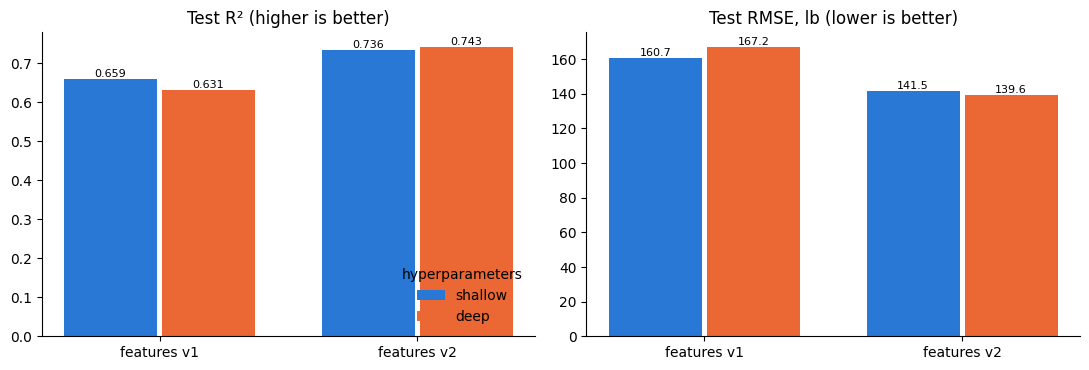

In [9]:
COLORS = {"shallow": "#2a78d6", "deep": "#eb6834"}   # one color per hyperparameter set

# Metrics read back from MLflow (latest run of each combo)
runs = (mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["start_time DESC"])
        .drop_duplicates("tags.mlflow.runName")
        .set_index("tags.mlflow.runName"))
cols = ["test_r2", "test_rmse", "test_mae", "train_r2", "train_seconds"]
table = runs.loc[list(results), [f"metrics.{c}" for c in cols]].set_axis(cols, axis=1)
table["overfit_gap"] = table["train_r2"] - table["test_r2"]
display(table.round(3))

titles = {"test_r2": "Test R² (higher is better)", "test_rmse": "Test RMSE, lb (lower is better)"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric in zip(axes, titles):
    for i, hp in enumerate(HPARAMS):
        vals = [table.loc[f"{v}_{hp}", metric] for v in FEATURE_VERSIONS]
        bars = ax.bar(np.arange(len(vals)) + (i - 0.5) * 0.38, vals, width=0.36,
                        color=COLORS[hp], label=hp)
        ax.bar_label(bars, fmt="%.3f" if metric == "test_r2" else "%.1f", fontsize=8)
    ax.set_xticks(range(len(FEATURE_VERSIONS)), [f"features {v}" for v in FEATURE_VERSIONS])
    ax.set_title(titles[metric])
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(title="hyperparameters", frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

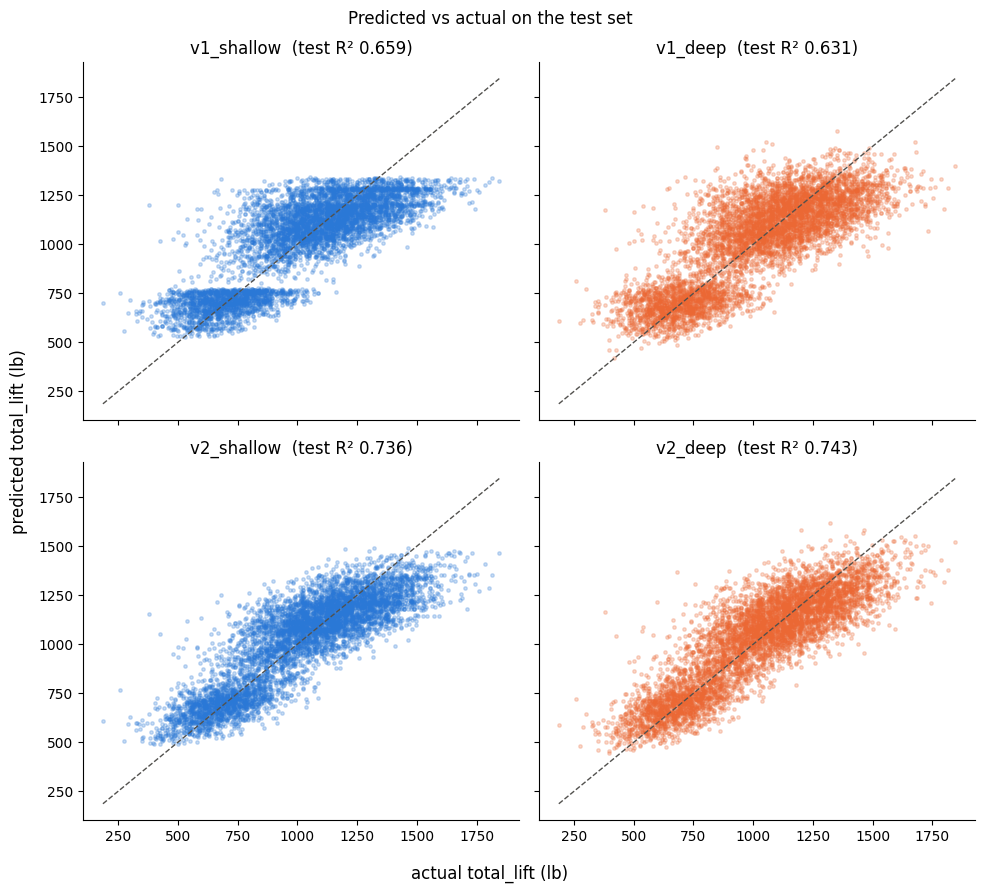

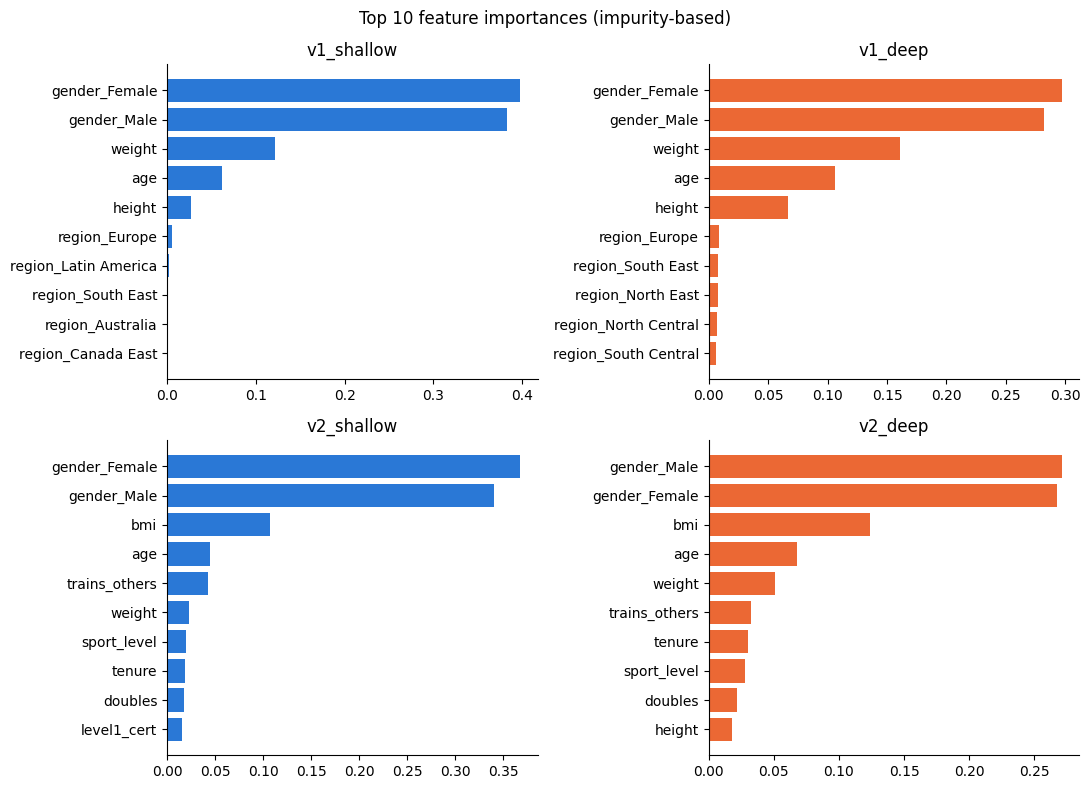

In [10]:
# Predicted vs actual (rows = feature version, columns = hyperparameters)
fig, axes = plt.subplots(2, 2, figsize=(10, 9), sharex=True, sharey=True)
for ax, (name, r) in zip(axes.flat, results.items()):
    ax.scatter(r["y_test"], r["pred"], s=6, alpha=0.25, color=COLORS[name.split("_")[1]])
    lims = [r["y_test"].min(), r["y_test"].max()]
    ax.plot(lims, lims, color="#52514e", lw=1, ls="--")       # perfect-prediction line
    ax.set_title(f"{name}  (test R² {r['test_r2']:.3f})")
    ax.spines[["top", "right"]].set_visible(False)
fig.supxlabel("actual total_lift (lb)")
fig.supylabel("predicted total_lift (lb)")
fig.suptitle("Predicted vs actual on the test set")
plt.tight_layout()
plt.show()

# Top 10 feature importances per run
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (name, r) in zip(axes.flat, results.items()):
    names = [n.split("__", 1)[1] for n in r["model"][0].get_feature_names_out()]
    imp = pd.Series(r["model"][-1].feature_importances_, index=names).nlargest(10).sort_values()
    ax.barh(imp.index, imp.values, color=COLORS[name.split("_")[1]])
    ax.set_title(name)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Top 10 feature importances (impurity-based)")
plt.tight_layout()
plt.show()

**Quantitative.** The feature version had a much bigger effect than the hyperparameters. With the v2 features (v1 plus BMI and the encoded survey answers), test R² went up from about 0.63 to 0.66 to about 0.74, and test RMSE dropped from 161 to 167 lb down to 140 to 142 lb, for both hyperparameter settings. The deep forest (300 trees with no depth limit) shows signs of overfitting: its train R² is much higher than its test R² (0.86 vs 0.63 for v1, 0.94 vs 0.74 for v2), while the shallow forest scores about the same on both (a gap under 0.01). On v1 the deep forest was even slightly worse than the shallow one (0.631 vs 0.659). A likely reason is that with only 5 features, many athletes look almost the same to the model but have very different total lifts, and a tree that keeps splitting until a leaf holds just 2 training athletes ends up matching those specific athletes, which does not seem to carry over to the test set. On v2 the deep forest was only 0.007 R² better but took about 5x longer to train, so **v2_shallow** looks like the best trade-off.

**Qualitative.** In the predicted vs actual plots, a perfect model would put every point on the dashed diagonal. For v1_shallow the points instead form two mostly flat bands, around 600 to 750 lb and 1,000 to 1,300 lb, which seem to be women and men, since gender is the most important feature in every run. Inside each band the prediction barely changes even when the actual lift changes by several hundred pounds, so with 5 features the model cannot tell athletes of the same gender apart very well. For both v2 models the points follow the diagonal more closely and the gap between the bands is mostly filled in, although all four models still underpredict the strongest athletes and overpredict the weakest. The feature importance plots point the same way: in v2, bmi takes the third place that weight held in v1, and the survey features (trains_others, tenure, sport_level, doubles) each add a small amount (about 0.02 to 0.04), which seems to be what helps separate athletes within the same gender.


### A.7 Compare the carbon emissions for the different experiments

,emissions_mg,energy_wh,train_seconds,mg_per_second,x_lowest,test_r2
tags.mlflow.runName,,,,,,
v1_shallow,4.705,0.019,2.772,1.697,1.515,0.659
v1_deep,88.758,0.362,43.073,2.061,28.582,0.631
v2_shallow,3.105,0.013,2.088,1.487,1.000,0.736
v2_deep,20.830,0.085,10.739,1.940,6.708,0.743


total for all 4 runs: 117.4 mg CO2-eq


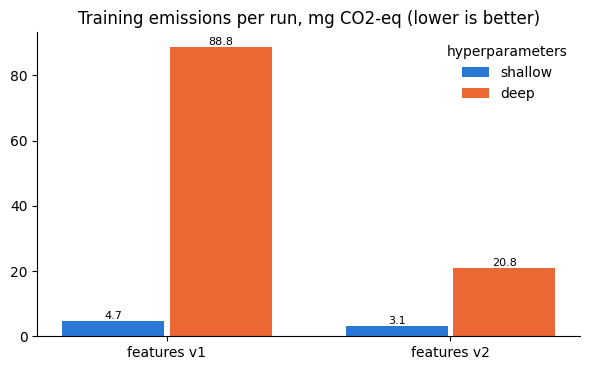

In [11]:
# Carbon emissions per run (CodeCarbon, training step only), read back from MLflow
cols = ["emissions_kg", "energy_kwh", "train_seconds", "test_r2"]
carbon = runs.loc[list(results), [f"metrics.{c}" for c in cols]].set_axis(cols, axis=1)
carbon["emissions_mg"] = carbon["emissions_kg"] * 1e6
carbon["energy_wh"] = carbon["energy_kwh"] * 1e3
carbon["mg_per_second"] = carbon["emissions_mg"] / carbon["train_seconds"]
carbon["x_lowest"] = carbon["emissions_kg"] / carbon["emissions_kg"].min()
display(carbon[["emissions_mg", "energy_wh", "train_seconds", "mg_per_second",
                "x_lowest", "test_r2"]].round(3))
print(f"total for all 4 runs: {carbon['emissions_mg'].sum():.1f} mg CO2-eq")

fig, ax = plt.subplots(figsize=(6, 3.8))
for i, hp in enumerate(HPARAMS):
    vals = [carbon.loc[f"{v}_{hp}", "emissions_mg"] for v in FEATURE_VERSIONS]
    bars = ax.bar(np.arange(len(vals)) + (i - 0.5) * 0.38, vals, width=0.36,
                    color=COLORS[hp], label=hp)
    ax.bar_label(bars, fmt="%.1f", fontsize=8)
ax.set_xticks(range(len(FEATURE_VERSIONS)), [f"features {v}" for v in FEATURE_VERSIONS])
ax.set_title("Training emissions per run, mg CO2-eq (lower is better)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="hyperparameters", frameon=False)
plt.tight_layout()
plt.show()

**Carbon emissions.** All four runs together emitted only about 117 mg of CO2-eq, so the absolute amounts are very small. The differences between runs are still large in relative terms. The two shallow runs emitted about 3 to 5 mg each, while the deep runs emitted about 21 mg (v2) and 89 mg (v1), roughly 7x and 28x the lowest run (v2_shallow).

The emissions per second of training are similar for all four runs (about 1.5 to 2.1 mg/s), so the differences come mostly from how long each run trained. The deep setting trains 3x more trees (300 vs 100) and lets each tree grow without a depth limit, so it takes longer and uses more energy. The v1_deep run took noticeably longer than v2_deep (43 s vs 11 s) even though v1 has fewer features, so part of its emissions may come from slowdowns on the laptop at the time rather than from the model settings themselves.

Combined with the metrics in A.6, v2_shallow looks like the best choice: it had the lowest emissions (about 3 mg) and its test R² (0.736) is within 0.01 of the best model (v2_deep, 0.743), which emitted about 7x more.